# Partie 6 : analyse critique

On prend du recul sur notre meilleur classifieur, celui recommandé en partie 2 :

- 6.1 où regarde le modèle quand il décide ? la maladie ou le fond ?
- 6.2 ses erreurs, au moins 10 images regardées une par une ;
- 6.3 ce qui changerait sur des photos prises au champ ;
- 6.4 les enjeux pour les maraîchers ;
- 6.5 les limites de notre prototype.

- On ajoute le dossier du projet au chemin de Python pour pouvoir importer notre code (`src/`).
- `config` contient les chemins, la maladie M choisie et le GPU utilisé.
- `set_seed(42)` fixe le hasard, pour retrouver les mêmes résultats à chaque exécution.
- La dernière ligne affiche la machine utilisée.

In [10]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # dossier du projet, pour pouvoir importer src/

from src import config as C
C.set_seed(42)
print(C.describe_env())

Python 3.12.10, torch 2.6.0+cu124, torchvision 0.21.0+cu124
Calcul sur : cuda
GPU : NVIDIA GeForce RTX 4080 Laptop GPU
CPU : 13th Gen Intel(R) Core(TM) i7-13650HX (20 coeurs logiques)


- On recharge le modèle recommandé en partie 2 et ses prédictions sur le test, déjà faites : on ne refait aucun choix sur le test.
- `ds` donne accès aux images du test, dans le même ordre que les prédictions.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import accuracy_score, f1_score

from src import data as D, viz
from src.models import load_classifier
from src.metrics import savefig
from src import explain as X

choix = C.load_json(C.RESULTS / "recommendation.json")              # modèle recommandé en partie 2
model, meta = load_classifier(C.CKPT_DIR / choix["run"] / "best.pt")
NORM = meta["norm"]
SIZE = meta["size"]
NOMS = []
for classe in D.CLASSES:
    NOMS.append(D.short(classe))

test = D.subset(D.load_splits(), split="test")
ds = D.LeafDataset(test, SIZE, D.get_transform("clf", False, NORM), D.CLASSES)
preds = pd.read_csv(C.RESULTS / "preds" / (choix["run"] + "_test.csv"))     # prédictions faites dans le notebook 02
nb_erreurs = (preds["y_true"] != preds["y_pred"]).sum()
print("Modèle :", choix["run"], "| erreurs sur le test :", nb_erreurs, "sur", len(preds))

Modèle : mobilenet_v3_large_last_third | erreurs sur le test : 11 sur 2725


## 6.1 Où regarde le modèle ? (Grad-CAM)

Grad-CAM colore les zones de l'image qui ont le plus pesé dans la décision du modèle : le rouge compte beaucoup, le bleu peu. La méthode se base sur la dernière couche de convolution et regarde comment chacune de ses cartes fait monter le score de la classe choisie.

- On prend 8 bonnes prédictions au hasard et les 8 erreurs où le modèle était le plus sûr de lui, les plus gênantes en pratique.
- Pour chaque image, on affiche l'image seule puis la carte Grad-CAM posée dessus, avec la vraie classe, la classe prédite et la confiance.

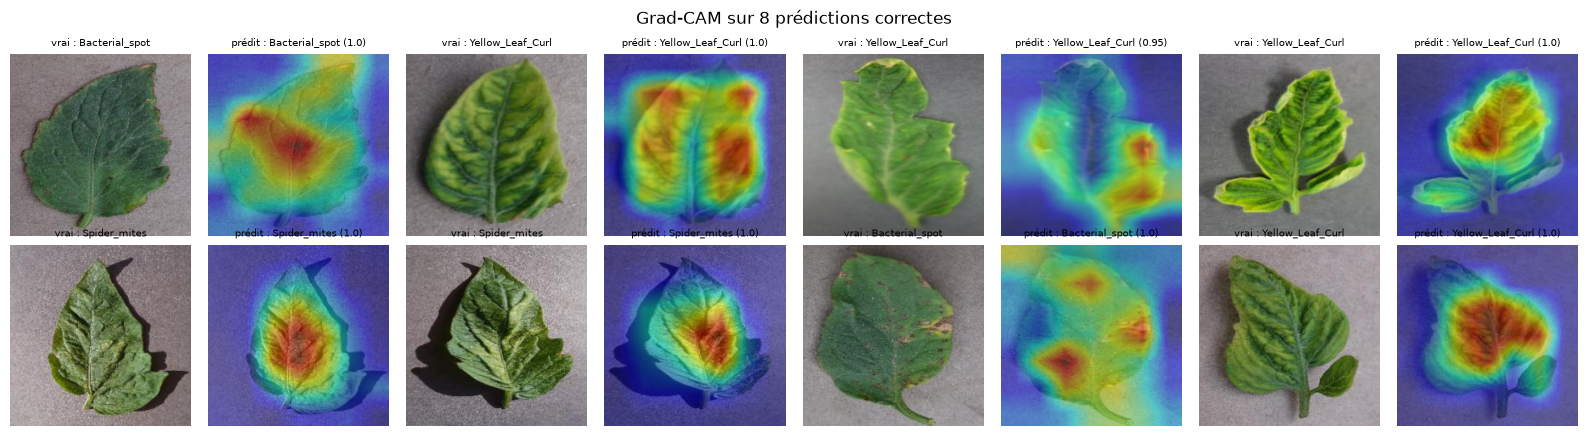

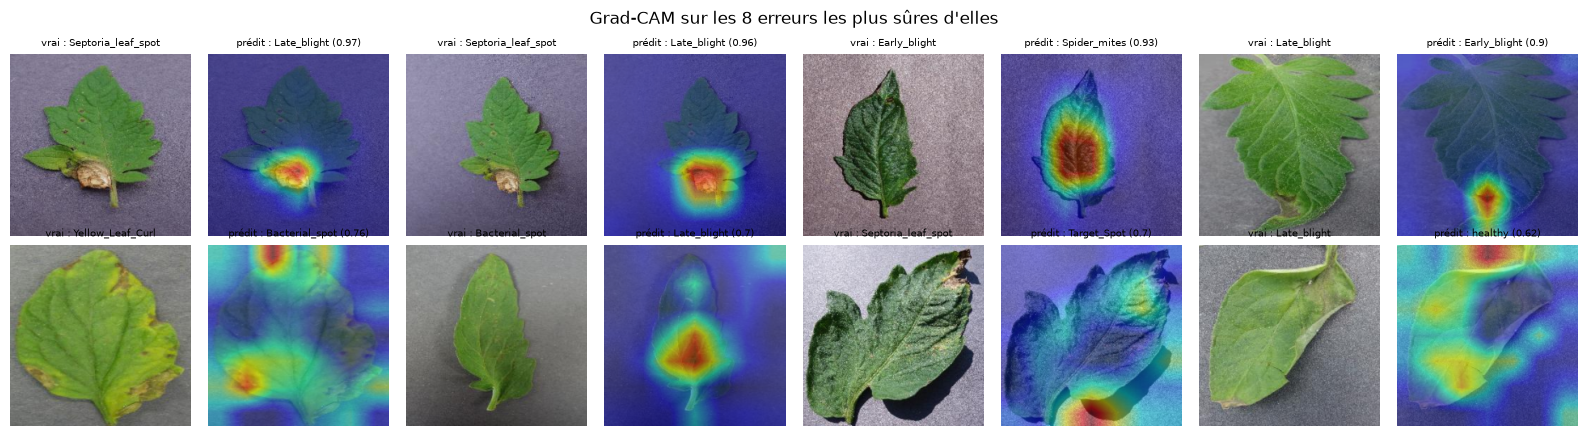

In [12]:
rng = np.random.default_rng(42)
indices_corrects = np.where(preds["y_true"] == preds["y_pred"])[0]

# 8 prédictions correctes au hasard
correctes = rng.choice(indices_corrects, 8, replace=False)             

indices_erreurs = np.where(preds["y_true"] != preds["y_pred"])[0]
# de la plus confiante à la moins confiante
ordre = np.argsort(-preds["msp"].values[indices_erreurs])  
# les 8 erreurs les plus sûres d'elles
erreurs = indices_erreurs[ordre][:8]                                     

def afficher_gradcam(indices, titre, fichier):
    images = []
    for i in indices:
        images.append(ds.get_uint8(i))     # image d'origine (pixels 0 à 255)
    cartes = X.gradcam_maps(model, model.cam_layer, X.to_model_input(images, NORM, C.DEVICE))
    grille, titres = [], []
    for k in range(len(indices)):
        i = indices[k]
        grille.append(images[k])
        # carte posée sur l'image
        grille.append(X.overlay(images[k], cartes[k]))                   
        titres.append("vrai : " + NOMS[preds["y_true"][i]])
        titres.append("prédit : " + NOMS[preds["y_pred"][i]] + " (" + str(round(preds["msp"][i], 2)) + ")")
    viz.image_grid(grille, titres, ncols=8, size=2, path=C.FIG_DIR / fichier, suptitle=titre)

afficher_gradcam(correctes, "Grad-CAM sur 8 prédictions correctes", "06_gradcam_correctes.png")
if len(erreurs) > 0:
    afficher_gradcam(erreurs, "Grad-CAM sur les 8 erreurs les plus sûres d'elles", "06_gradcam_erreurs.png")

### Le modèle se sert-il du fond ?

Les cartes donnent une idée, mais ne prouvent rien. On fait donc un test chiffré. On découpe la feuille (elle est plus colorée que le fond gris, ce qui permet de la séparer), puis on remplace le fond par du noir, du bruit ou une texture de sol, et on regarde si les résultats sur le test changent.

Si le modèle regarde vraiment la feuille, le score doit à peine bouger. S'il chute, c'est que le modèle s'aide du fond du laboratoire : c'est ce qu'on appelle un raccourci (shortcut learning).

- On affiche 6 exemples : l'image, le masque de la feuille (en blanc), puis la feuille sur un fond de bruit et sur un fond de sol.
- À vérifier à l'oeil avant de lire les chiffres : si le masque coupe la feuille, le test n'est pas fiable.
- La texture de sol est une texture de terre brune générée au hasard (avec une seed fixe). Nos photos personnelles montrent surtout des objets, elles ne conviennent pas comme fond de terre.

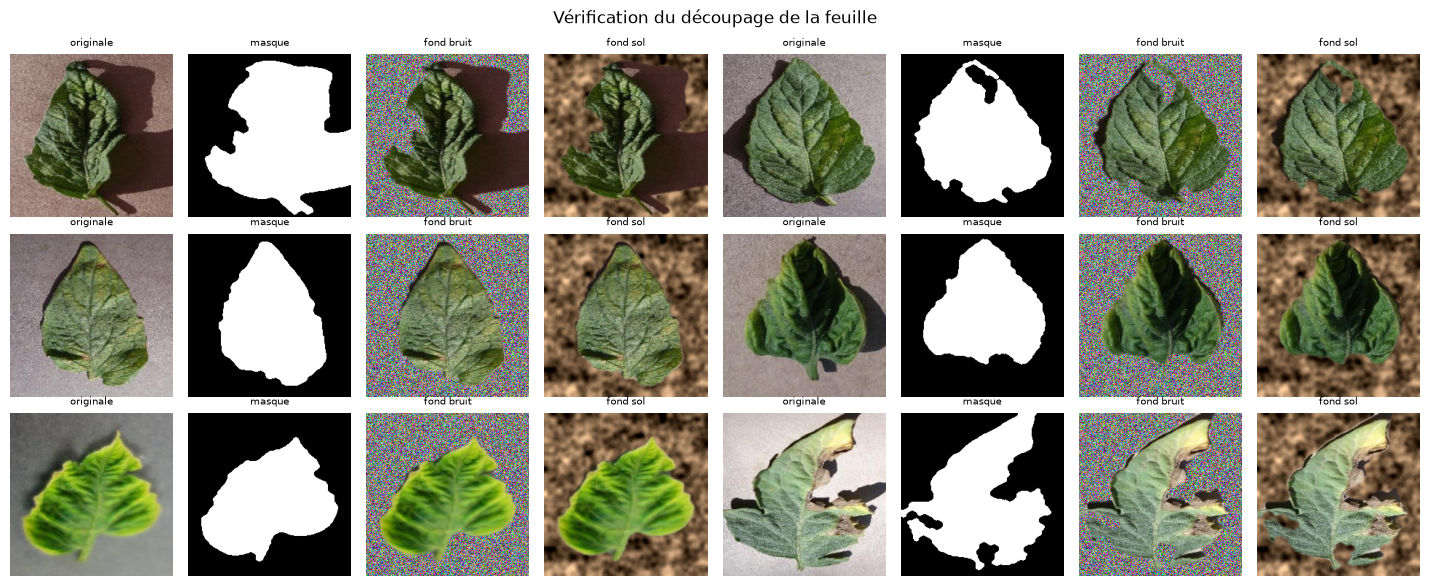

In [13]:
# texture de terre brune générée : nos photos du dossier sol_objets montrent surtout des objets, pas de la terre
photos_sol = None

grille, titres = [], []
for i in rng.choice(len(ds), 6, replace=False):
    img = ds.get_uint8(i)
    masque = X.leaf_mask(img)                                            # True sur la feuille, False sur le fond
    image_masque = np.stack([masque, masque, masque], axis=2).astype(np.uint8) * 255
    grille.append(img)
    grille.append(image_masque)
    grille.append(X.replace_background(img, masque, "noise", np.random.default_rng(0)))
    grille.append(X.replace_background(img, masque, "soil", np.random.default_rng(0), photos_sol))
    titres += ["originale", "masque", "fond bruit", "fond sol"]
viz.image_grid(grille, titres, ncols=8, size=1.8, path=C.FIG_DIR / "06_segmentation.png",
               suptitle="Vérification du découpage de la feuille")

- Pour chaque fond (d'origine, noir, bruit, sol), on remplace le fond de toutes les images du test, 64 par 64, puis on prédit.
- On calcule l'accuracy et le F1 macro, et de combien de points le F1 baisse par rapport aux images d'origine.
- Les résultats sont enregistrés dans `results/background_test.json`.

In [14]:
resultats = {}
for fond in ["original", "black", "noise", "soil"]:
    hasard = np.random.default_rng(42)
    predictions = []
    for debut in range(0, len(ds), 64):    
        # par paquets de 64 images
        lot = []
        for i in range(debut, min(debut + 64, len(ds))):
            img = ds.get_uint8(i)
            if fond != "original":
                img = X.replace_background(img, X.leaf_mask(img), fond, hasard, photos_sol)
            lot.append(img)
        with torch.inference_mode():
            sorties = model(X.to_model_input(lot, NORM, C.DEVICE))
        predictions += sorties.argmax(dim=1).cpu().tolist()
    acc = accuracy_score(ds.labels, predictions)
    f1 = f1_score(ds.labels, predictions, average="macro")
    resultats[fond] = {"accuracy": round(acc, 4), "F1 macro": round(f1, 4)}
    print(fond, ": accuracy", round(acc, 4), "| F1 macro", round(f1, 4))

f1_origine = resultats["original"]["F1 macro"]
for fond in resultats:
    resultats[fond]["baisse du F1 (points)"] = round(100 * (f1_origine - resultats[fond]["F1 macro"]), 1)
C.save_json(resultats, C.RESULTS / "background_test.json")
pd.DataFrame(resultats).T

original : accuracy 0.996 | F1 macro 0.9955
black : accuracy 0.3266 | F1 macro 0.292
noise : accuracy 0.3417 | F1 macro 0.288
soil : accuracy 0.4848 | F1 macro 0.321


,accuracy,F1 macro,baisse du F1 (points)
original,0.9960,0.9955,0.0
black,0.3266,0.2920,70.3
noise,0.3417,0.2880,70.8
soil,0.4848,0.3210,67.5


- Les mêmes images avant et après avoir mis un fond de sol : est-ce que la zone rouge se déplace ? Est-ce que la prédiction change ?

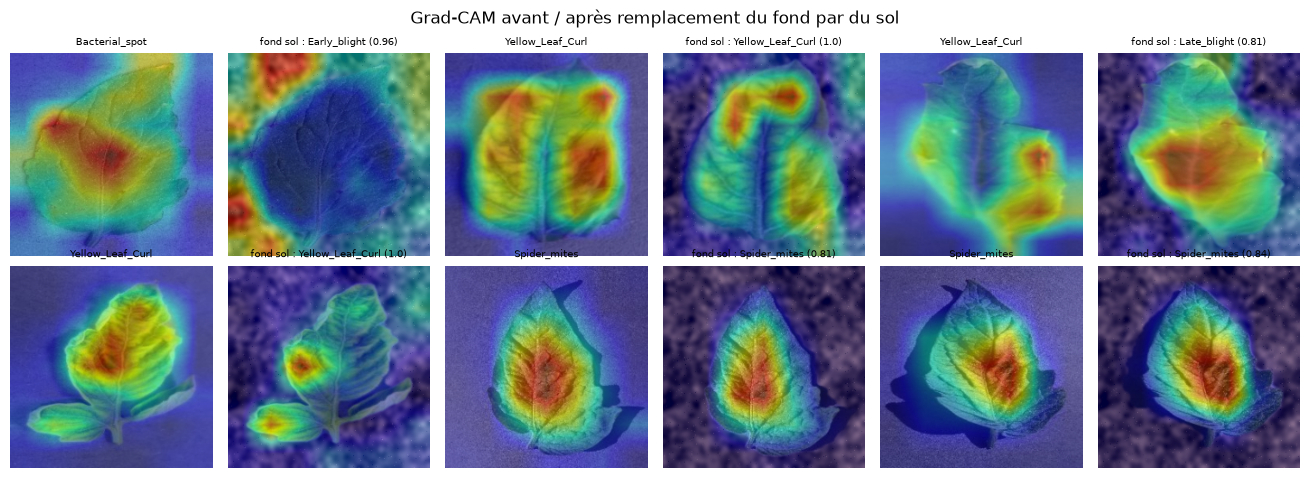

In [15]:
indices = correctes[:6]
originales, avec_sol = [], []
for i in indices:
    img = ds.get_uint8(i)
    originales.append(img)
    avec_sol.append(X.replace_background(img, X.leaf_mask(img), "soil", np.random.default_rng(1), photos_sol))
cartes_1 = X.gradcam_maps(model, model.cam_layer, X.to_model_input(originales, NORM, C.DEVICE))
cartes_2 = X.gradcam_maps(model, model.cam_layer, X.to_model_input(avec_sol, NORM, C.DEVICE))
with torch.inference_mode():
    proba_sol = model(X.to_model_input(avec_sol, NORM, C.DEVICE)).softmax(dim=1).cpu().numpy()

grille, titres = [], []
for k in range(len(indices)):
    grille.append(X.overlay(originales[k], cartes_1[k]))
    grille.append(X.overlay(avec_sol[k], cartes_2[k]))
    titres.append(NOMS[preds["y_true"][indices[k]]])
    titres.append("fond sol : " + NOMS[proba_sol[k].argmax()] + " (" + str(round(proba_sol[k].max(), 2)) + ")")
viz.image_grid(grille, titres, ncols=6, size=2.2, path=C.FIG_DIR / "06_gradcam_fond_sol.png",
               suptitle="Grad-CAM avant / après remplacement du fond par du sol")

### Ce qu'on observe

- **Sur les bonnes prédictions**, la zone rouge est le plus souvent sur la feuille : sur les taches pour Bacterial_spot, sur les zones jaunies entre les nervures pour Yellow_Leaf_Curl, au centre de la feuille pour Spider_mites. C'est rassurant, mais pas parfait : sur certaines images, la chaleur déborde aussi sur le fond gris autour de la feuille.
- **Sur les erreurs**, c'est moins propre. Pour les deux Septoria prises pour du Late_blight, le modèle regarde surtout le morceau de feuille sèche et brune près de la tige, et ignore les petites taches rondes typiques de la Septoria. Pour d'autres erreurs (Yellow_Leaf_Curl prise pour Bacterial_spot, Septoria prise pour Target_Spot, Late_blight prise pour healthy), le rouge tombe en grande partie sur le fond ou sur l'ombre, pas sur la feuille.
- **Le test du fond est très net.** Avec le fond d'origine, le F1 macro est de 0,996. Dès qu'on remplace le fond, il tombe à 0,29 avec un fond noir, 0,29 avec du bruit et 0,32 avec de la terre. Le modèle perd donc environ 70 points de F1 alors que la feuille, elle, n'a pas changé.
- **Les cartes avant / après le fond de sol** montrent la même chose. Une feuille de Bacterial_spot devient « Early_blight » avec 96 % de confiance, et la zone rouge part sur la terre dans les coins de l'image. Une Yellow_Leaf_Curl devient « Late_blight ». Seules les Spider_mites restent bien classées, avec une carte qui ne bouge presque pas.

**Ce qu'on en retient.** Le modèle a appris en partie un raccourci : il se sert du fond uni du laboratoire pour décider. Avec nos 99,6 % sur le test, on pourrait croire le problème résolu, mais ce chiffre ne dit rien de ce qui se passera au champ, où le fond est toujours de la terre, d'autres feuilles ou des mains.

Une précaution : notre découpage de la feuille n'est pas parfait. Sur la figure de vérification, l'ombre est parfois gardée avec la feuille, et une feuille très pâle sur fond clair est mal découpée. Le nouveau fond peut donc contenir un bout de l'ancien, ou couper un peu de feuille. Cela n'explique pas une chute de 70 points, mais la valeur exacte est à prendre avec prudence.

## 6.2 Analyse des erreurs

- On garde les images mal classées, avec le nom de la vraie classe et de la classe prédite.
- On compte les confusions les plus fréquentes.
- On affiche jusqu'à 20 erreurs, numérotées, pour les regarder une par une et les ranger par famille dans le tableau ci-dessous.

Confusions les plus fréquentes :
vrai                prédit        
Early_blight        Spider_mites      2
Late_blight         Early_blight      2
Septoria_leaf_spot  Late_blight       2
Bacterial_spot      Late_blight       1
Late_blight         Bacterial_spot    1
                    healthy           1
Septoria_leaf_spot  Target_Spot       1
Yellow_Leaf_Curl    Bacterial_spot    1
dtype: int64


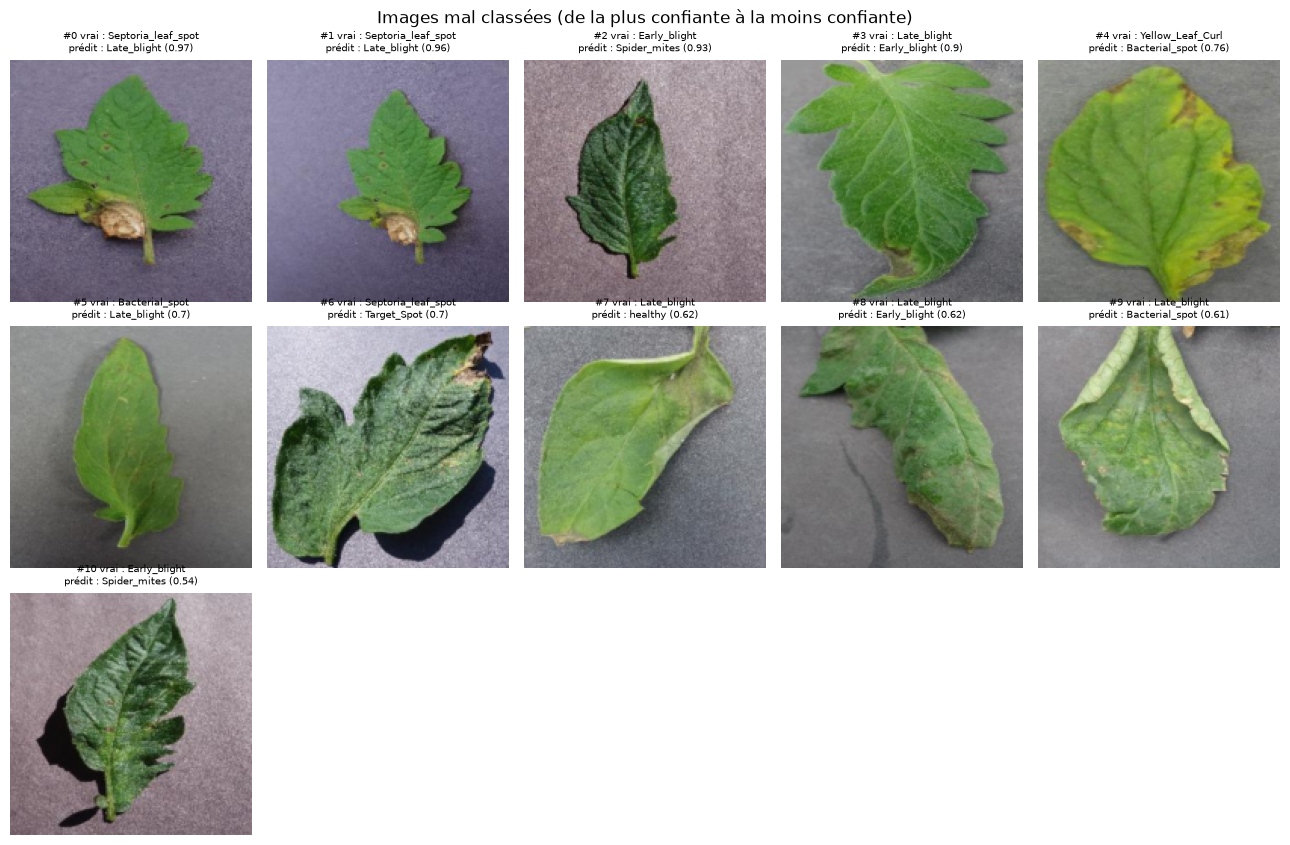

,path,vrai,prédit,msp
0,raw/Tomato___Septoria_leaf_spot/ba5de483-365d-...,Septoria_leaf_spot,Late_blight,0.965380
1,raw/Tomato___Septoria_leaf_spot/9a453d1c-52cd-...,Septoria_leaf_spot,Late_blight,0.963506
2,raw/Tomato___Early_blight/cd76ee4d-d516-4189-b...,Early_blight,Spider_mites,0.925278
3,raw/Tomato___Late_blight/43eb2436-bdba-4f67-8f...,Late_blight,Early_blight,0.902479
4,raw/Tomato___Tomato_Yellow_Leaf_Curl_Virus/1ab...,Yellow_Leaf_Curl,Bacterial_spot,0.756163
5,raw/Tomato___Bacterial_spot/88a4e8ec-ef71-4847...,Bacterial_spot,Late_blight,0.702463
6,raw/Tomato___Septoria_leaf_spot/e65190f0-97e9-...,Septoria_leaf_spot,Target_Spot,0.696797
7,raw/Tomato___Late_blight/bb41f69c-b5b4-4acb-b9...,Late_blight,healthy,0.621541
8,raw/Tomato___Late_blight/a06d18d4-0c8d-4ebc-ba...,Late_blight,Early_blight,0.619166
9,raw/Tomato___Late_blight/15581dd8-f562-4301-85...,Late_blight,Bacterial_spot,0.607967


In [16]:
mal_classees = preds[preds["y_true"] != preds["y_pred"]].copy()
vrais, predits = [], []
for k in range(len(mal_classees)):
    vrais.append(NOMS[mal_classees["y_true"].iloc[k]])
    predits.append(NOMS[mal_classees["y_pred"].iloc[k]])
mal_classees["vrai"] = vrais
mal_classees["prédit"] = predits

print("Confusions les plus fréquentes :")
print(mal_classees.groupby(["vrai", "prédit"]).size().sort_values(ascending=False).head(10))

a_voir = mal_classees.sort_values("msp", ascending=False).head(20)      # jusqu'à 20 erreurs, les plus confiantes d'abord
images, titres = [], []
for k in range(len(a_voir)):
    ligne = a_voir.iloc[k]
    images.append(D.read_rgb(C.resolve(ligne["path"]), 160))
    titres.append("#" + str(k) + " vrai : " + ligne["vrai"] + "\nprédit : " + ligne["prédit"] + " (" + str(round(ligne["msp"], 2)) + ")")
viz.image_grid(images, titres, ncols=5, size=2.6, title_fs=7, path=C.FIG_DIR / "06_erreurs.png",
               suptitle="Images mal classées (de la plus confiante à la moins confiante)")
a_voir[["path", "vrai", "prédit", "msp"]].reset_index(drop=True)

### Familles d'erreurs

Le modèle se trompe sur 11 images sur 2 725. Voici comment on les range, en regardant les images et les cartes Grad-CAM.

| Famille | Images (#) | Explication |
|---|---|---|
| Maladies qui se ressemblent | #2, #3, #6, #8, #10 | Late_blight, Early_blight et Target_Spot font toutes des taches brunes, difficiles à distinguer sur une petite image. Pour #2 et #10, la feuille est sombre et granuleuse, ce qui ressemble à une feuille attaquée par les acariens (Spider_mites). |
| Maladie au tout début, peu visible | #5, #7 | Il y a très peu de taches et la feuille paraît presque saine. Pour #7, le modèle répond même « healthy ». |
| Plusieurs maladies sur la même feuille | #4 | La feuille est jaunie, comme avec le virus, mais elle a aussi des taches brunes sur les bords, qui font penser à Bacterial_spot. |
| Image floue, sombre ou feuille abîmée | #0, #1, #9 | #0 et #1 sont presque la même photo : un morceau de feuille sèche près de la tige attire toute l'attention du modèle (voir Grad-CAM), qui en oublie les petites taches de Septoria. #9 est enroulée, on voit mal sa surface. |
| Étiquette sans doute fausse | aucune certaine | Sans l'avis d'un agronome, on ne peut pas affirmer qu'une étiquette est fausse. |

**Bilan.** La moitié des erreurs viennent de maladies à taches brunes qui se ressemblent, et les autres de feuilles où les signes sont faibles ou cachés. Le modèle est parfois très sûr de lui quand il se trompe (0,97 pour #0) : la confiance seule ne suffit pas pour repérer une erreur, ce qui justifie le système de rejet de la partie 4.

## 6.3 Du laboratoire au champ

Dans PlantVillage, chaque feuille est cueillie, posée seule au centre de l'image, sur un fond uni et sous une lumière bien réglée. Dans un champ des Niayes, c'est très différent : il y a le sol, d'autres feuilles, des mains, des ombres, le soleil fort de midi, des photos floues prises avec des téléphones simples, des variétés locales qui ne ressemblent pas forcément à celles du jeu de données, et souvent plusieurs maladies sur la même plante.

Pour avoir un modèle utilisable sur le terrain, il faudrait collecter des photos dans les Niayes et la vallée du fleuve, le matin, à midi et le soir, avec les téléphones que les maraîchers utilisent vraiment et la feuille encore sur la plante. Ces photos devraient être étiquetées par un agent agricole, avec la possibilité d'indiquer plusieurs maladies ou « je ne sais pas ». Et il faudrait garder à part des photos d'autres parcelles et d'une autre saison, pour mesurer la vraie performance.

## 6.4 Enjeux pour les maraîchers

Le modèle peut se tromper de deux façons, et elles n'ont pas les mêmes conséquences. S'il dit qu'une feuille malade est saine (faux négatif), la maladie n'est pas traitée, elle s'étend et le maraîcher perd une partie de sa récolte et de son revenu. S'il invente une maladie (faux positif), le maraîcher achète un traitement inutile et met plus de pesticides sur ses tomates, et sur lui-même.

C'est pour ça que notre système répond « inconnu, consultez un agent agricole » quand il n'est pas sûr. La partie 4 montre que c'est nécessaire : sans rejet, le classifieur a donné un diagnostic avec plus de 99 % de confiance sur des photos de mains. Avec la règle OU, il rejette toutes nos photos de mains, 85 % de nos photos d'objets et 60 % des feuilles d'une maladie qu'il n'a jamais apprise. Le prix à payer est raisonnable : environ 5 % des feuilles connues sont renvoyées à tort vers un agent. L'outil aide à repérer un problème, mais la décision de traiter reste à un humain.

Pour être vraiment utile, l'application doit marcher sans internet, sur un petit téléphone (d'où un modèle léger), et parler la langue des maraîchers : wolof, pulaar, ou des images et des messages vocaux.

## 6.5 Limites et pistes

Nos très bons scores viennent d'images de laboratoire. Le test du fond le montre clairement : le F1 passe de 0,996 à environ 0,30 quand on change seulement le fond. On ne peut donc pas s'attendre aux mêmes résultats au champ. Nous n'avons testé qu'une seule maladie inconnue ; il faudrait refaire l'essai avec d'autres, surtout une maladie qui ressemble à une autre. L'auto-encodeur et le VAE détectent mal les maladies (AUROC autour de 0,63) : ils sont surtout sensibles à la couleur, au fond et à l'éclairage, et pas aux petites taches. Prendre le maximum local de l'erreur au lieu de la moyenne n'a pas aidé (partie 3), et le VAE ne fait pas mieux (partie 5). Et nos seuils sont réglés pour accepter 95 % des images connues : il faudrait plutôt les fixer avec des agents agricoles, selon ce que coûte vraiment chaque erreur.

Pour aller plus loin : collecter des photos de terrain, entraîner le modèle avec des fonds variés (par exemple en remplaçant le fond pendant l'entraînement, avec le même masque que dans ce notebook), découper la feuille avant de la classer, et tester l'application avec de vrais maraîchers.

## Tableau récapitulatif

Le tableau demandé dans les livrables : une ligne par expérience, construite à partir de `results/summary.csv`, que chaque notebook a rempli.

- On relit `summary.csv` et on garde les colonnes utiles, dans un ordre lisible.
- Le tableau est enregistré dans `results/tableau_recapitulatif.csv`. Une case vide veut dire que la mesure ne concerne pas cette expérience : par exemple, les runs de l'étude du LR ne sont jamais évalués sur le test, seulement sur la validation.
- À relancer à la toute fin, quand tous les notebooks ont tourné.

In [17]:
resume = pd.read_csv(C.SUMMARY_CSV)
colonnes = ["partie", "experiment", "modele", "resolution", "hyperparametres", "params", "taille_mo",
            "temps_entrainement_s", "latence_cpu_ms", "latence_gpu_ms", "val_f1", "test_acc", "test_f1_macro",
            "test_auroc", "test_rappel_anomalies", "test_fausses_alarmes", "test_rejet_M", "test_rejet_a_tort", "test_acc_acceptes"]
colonnes_presentes = []
for col in colonnes:
    if col in resume.columns:
        colonnes_presentes.append(col)
resume = resume[colonnes_presentes]
resume.to_csv(C.RESULTS / "tableau_recapitulatif.csv", index=False)
resume = resume.fillna("")
resume

,partie,experiment,modele,resolution,hyperparametres,params,taille_mo,temps_entrainement_s,latence_cpu_ms,latence_gpu_ms,val_f1,test_acc,test_f1_macro,test_auroc,test_rappel_anomalies,test_fausses_alarmes,test_rejet_M,test_rejet_a_tort,test_acc_acceptes
0,1,P1_CNN-Res_lr=0.1,CNN-Res,,"Adam lr=0.1, batch 64, 10 époques",,,224.6,,,0.7465,,,,,,,,
1,1,P1_CNN-Res_lr=0.01,CNN-Res,,"Adam lr=0.01, batch 64, 10 époques",,,232.6,,,0.9191,,,,,,,,
2,1,P1_CNN-Res_lr=0.001,CNN-Res,,"Adam lr=0.001, batch 64, 10 époques",,,207.1,,,0.9662,,,,,,,,
3,1,P1_CNN-Res_lr=0.0001,CNN-Res,,"Adam lr=0.0001, batch 64, 10 époques",,,221.7,,,0.9524,,,,,,,,
4,1,P1_CNN-Plain,CNN-Plain,128.0,"Adam lr=0.001, batch 64, 15 époques",1336458.0,5.36,231.9,22.05,2.119,0.9705,0.9703,0.9612,,,,,,
5,1,P1_CNN-Res,CNN-Res,128.0,"Adam lr=0.001, batch 64, 15 époques",1190922.0,4.79,359.3,62.41,0.886,0.9738,0.9717,0.966,,,,,,
6,2,P2_mobilenet_v3_large_frozen,mobilenet_v3_large,224.0,"frozen, lr tête 0.001, lr backbone None, 5 épo...",4214842.0,17.07,102.7,13.44,5.208,0.9537,0.9567,0.9479,,,,,,
7,2,P2_mobilenet_v3_large_last_third,mobilenet_v3_large,224.0,"last_third, lr tête 0.001, lr backbone 0.0001,...",4214842.0,17.07,90.7,13.44,5.208,0.9916,0.996,0.9955,,,,,,
8,2,P2_mobilenet_v3_large_full,mobilenet_v3_large,224.0,"full, lr tête 0.001, lr backbone 1e-05, 5 époques",4214842.0,17.07,115.7,13.44,5.208,0.9721,0.982,0.9778,,,,,,
9,2,P2_resnet50_last_third,resnet50,224.0,"last_third, lr tête 0.001, lr backbone 0.0001,...",23528522.0,94.44,122.8,111.36,6.625,0.9904,0.9927,0.9913,,,,,,
